In [4]:
# import required libraries

import pandas as pd
import numpy as np
import time

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from skopt import BayesSearchCV
from skopt.space import Integer, Real, Categorical

from hyperopt import fmin, tpe, hp, Trials, STATUS_OK

In [5]:
# load pharmacy sales dataset

df = pd.read_csv("global_pharmacy_sales_data.csv")

print("dataset shape:", df.shape)
display(df.head())

print("\nmissing values:")
print(df.isnull().sum())

dataset shape: (177990, 14)


,date,year,month,day,region,country,category,medicine,age_group,units_sold,unit_price,stock_level,expiry_days_remaining,covid_flag
0,2025-10-12,2025,10,12,Middle East,UAE,Chronic,Amlodipine,0-12,328,45.38,4774,466,0
1,2020-09-15,2020,9,15,South Asia,India,Chronic,Amlodipine,26-45,371,75.49,4584,181,1
2,2020-02-26,2020,2,26,Middle East,UAE,Vitamin,Vitamin C,0-12,948,22.51,3934,556,1
3,2025-11-09,2025,11,9,South Asia,Sri Lanka,Chronic,Amlodipine,0-12,275,63.29,4544,330,0
4,2022-04-04,2022,4,4,South America,Argentina,Chronic,Amlodipine,26-45,563,44.28,4284,590,0



missing values:
date                     0
year                     0
month                    0
day                      0
region                   0
country                  0
category                 0
medicine                 0
age_group                0
units_sold               0
unit_price               0
stock_level              0
expiry_days_remaining    0
covid_flag               0
dtype: int64


In [6]:
# prepare input features and target variable

target = "units_sold"

# convert date into datetime and extract useful date features
if "date" in df.columns:
    df["date"] = pd.to_datetime(df["date"], errors="coerce")

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day

    df.drop(columns=["date"], inplace=True)

# remove rows where target is missing
df = df.dropna(subset=[target])

X = df.drop(columns=[target])
y = df[target]

# identify numerical and categorical columns
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("numerical columns:", numeric_cols)
print("categorical columns:", categorical_cols)

print("feature shape:", X.shape)
print("target shape:", y.shape)

numerical columns: ['year', 'month', 'day', 'unit_price', 'stock_level', 'expiry_days_remaining', 'covid_flag']
categorical columns: ['region', 'country', 'category', 'medicine', 'age_group']
feature shape: (177990, 12)
target shape: (177990,)


In [7]:
# split data and select smaller samples for faster optimization

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# use smaller samples to reduce training time
tune_size = min(4000, len(X_train))
test_size = min(3000, len(X_test))

X_tune = X_train.sample(n=tune_size, random_state=42)
y_tune = y_train.loc[X_tune.index]

X_eval = X_test.sample(n=test_size, random_state=42)
y_eval = y_test.loc[X_eval.index]

print("optimization sample:", X_tune.shape)
print("evaluation sample:", X_eval.shape)

optimization sample: (4000, 12)
evaluation sample: (3000, 12)


In [8]:
# create preprocessing pipeline for numerical and categorical features

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

# create base regression pipeline
base_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

In [9]:
# define hyperparameter search space for gaussian process bayesian optimization

search_space = {
    "model__n_estimators": Integer(30, 70),
    "model__max_depth": Integer(5, 20),
    "model__min_samples_split": Integer(2, 12),
    "model__min_samples_leaf": Integer(1, 6),
    "model__max_features": Real(0.5, 1.0),
    "model__bootstrap": Categorical([True, False])
}

# use two-fold cross-validation
cv = KFold(n_splits=2, shuffle=True, random_state=42)

In [10]:
# optimize hyperparameters using gaussian process and expected improvement

bayes_start = time.time()

bayes_optimizer = BayesSearchCV(
    estimator=base_model,
    search_spaces=search_space,
    n_iter=6,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=2,
    random_state=42,
    optimizer_kwargs={
        "base_estimator": "GP",
        "acq_func": "EI"
    },
    verbose=0
)

bayes_optimizer.fit(X_tune, y_tune)

bayes_time = time.time() - bayes_start

print("best scikit-optimize parameters:")
print(bayes_optimizer.best_params_)

print("\nbest cross-validation RMSE:")
print(-bayes_optimizer.best_score_)

print("\noptimization time:", round(bayes_time, 2), "seconds")

best scikit-optimize parameters:
OrderedDict({'model__bootstrap': True, 'model__max_depth': 16, 'model__max_features': 0.966433999423917, 'model__min_samples_leaf': 3, 'model__min_samples_split': 9, 'model__n_estimators': 47})

best cross-validation RMSE:
111.58533004343684

optimization time: 12.66 seconds


In [11]:
# define hyperparameter search space for tpe optimization

hyperopt_space = {
    "n_estimators": hp.quniform("n_estimators", 30, 70, 10),
    "max_depth": hp.quniform("max_depth", 5, 20, 1),
    "min_samples_split": hp.quniform("min_samples_split", 2, 12, 1),
    "min_samples_leaf": hp.quniform("min_samples_leaf", 1, 6, 1),
    "max_features": hp.uniform("max_features", 0.5, 1.0),
    "bootstrap": hp.choice("bootstrap", [True, False])
}

In [12]:
# optimize hyperparameters using hyperopt tree structured parzen estimator

def objective(params):

    params["n_estimators"] = int(params["n_estimators"])
    params["max_depth"] = int(params["max_depth"])
    params["min_samples_split"] = int(params["min_samples_split"])
    params["min_samples_leaf"] = int(params["min_samples_leaf"])

    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=1,
            **params
        ))
    ])

    scores = cross_val_score(
        model,
        X_tune,
        y_tune,
        cv=cv,
        scoring="neg_root_mean_squared_error",
        n_jobs=2
    )

    # hyperopt minimizes the objective value
    return {
        "loss": -scores.mean(),
        "status": STATUS_OK
    }


# store optimization trials
trials = Trials()

hyperopt_start = time.time()

best_hyperopt = fmin(
    fn=objective,
    space=hyperopt_space,
    algo=tpe.suggest,
    max_evals=6,
    trials=trials,
    rstate=np.random.default_rng(42),
    show_progressbar=True
)

hyperopt_time = time.time() - hyperopt_start

# convert selected hyperparameters into model format
best_hyperopt_params = {
    "n_estimators": int(best_hyperopt["n_estimators"]),
    "max_depth": int(best_hyperopt["max_depth"]),
    "min_samples_split": int(best_hyperopt["min_samples_split"]),
    "min_samples_leaf": int(best_hyperopt["min_samples_leaf"]),
    "max_features": float(best_hyperopt["max_features"]),
    "bootstrap": [True, False][best_hyperopt["bootstrap"]]
}

print("best hyperopt parameters:")
print(best_hyperopt_params)

print("\noptimization time:", round(hyperopt_time, 2), "seconds")

100%|██████████| 6/6 [00:07<00:00,  1.27s/trial, best loss: 101.5832855971166] 
best hyperopt parameters:
{'n_estimators': 50, 'max_depth': 10, 'min_samples_split': 3, 'min_samples_leaf': 2, 'max_features': 0.673059298817251, 'bootstrap': False}

optimization time: 7.64 seconds


In [13]:
# train both optimized models using their best hyperparameters

bayes_model = bayes_optimizer.best_estimator_

hyperopt_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=1,
        **best_hyperopt_params
    ))
])

hyperopt_model.fit(X_tune, y_tune)

print("both optimized models are trained successfully")

both optimized models are trained successfully


In [14]:
# evaluate optimized models using regression performance metrics

models = {
    "scikit-optimize": bayes_model,
    "hyperopt": hyperopt_model
}

results = []

for name, model in models.items():

    predictions = model.predict(X_eval)

    rmse = np.sqrt(mean_squared_error(y_eval, predictions))
    mae = mean_absolute_error(y_eval, predictions)
    r2 = r2_score(y_eval, predictions)

    results.append({
        "optimization_method": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,optimization_method,RMSE,MAE,R2 Score
0,scikit-optimize,80.6581,64.1671,0.9145
1,hyperopt,83.8103,64.3996,0.9077


In [15]:
# compare execution time of both bayesian optimization frameworks

time_comparison = pd.DataFrame({
    "Method": ["scikit-optimize", "hyperopt"],
    "Optimization Time (seconds)": [
        bayes_time,
        hyperopt_time
    ]
})

display(time_comparison.round(2))

,Method,Optimization Time (seconds)
0,scikit-optimize,12.66
1,hyperopt,7.64


In [16]:
# analyze hyperopt trial results to understand optimization progress

trial_results = pd.DataFrame([
    {
        "trial": i + 1,
        "RMSE": trial["result"]["loss"],
        "status": trial["result"]["status"]
    }
    for i, trial in enumerate(trials.trials)
])

display(trial_results.round(4))

print("best hyperopt trial RMSE:")
print(round(trial_results["RMSE"].min(), 4))

,trial,RMSE,status
0,1,116.0654,ok
1,2,129.5961,ok
2,3,114.2416,ok
3,4,107.5184,ok
4,5,101.5833,ok
5,6,108.1007,ok


best hyperopt trial RMSE:
101.5833


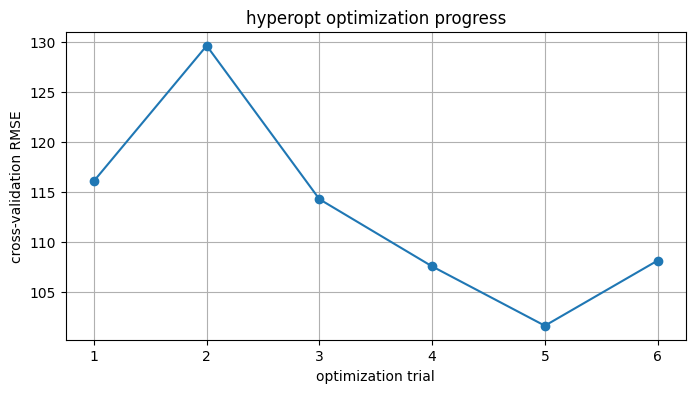

In [17]:
# visualize the optimization progress of hyperopt

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(
    trial_results["trial"],
    trial_results["RMSE"],
    marker="o"
)

plt.xlabel("optimization trial")
plt.ylabel("cross-validation RMSE")
plt.title("hyperopt optimization progress")
plt.grid(True)
plt.show()

In [18]:
# identify the best performing optimization method

best_result = results_df.loc[
    results_df["RMSE"].idxmin()
]

print("best optimization method:", best_result["optimization_method"])
print("best RMSE:", round(best_result["RMSE"], 4))
print("best MAE:", round(best_result["MAE"], 4))
print("best R2 score:", round(best_result["R2 Score"], 4))

best optimization method: scikit-optimize
best RMSE: 80.6581
best MAE: 64.1671
best R2 score: 0.9145
